# Building a Perceptron from Scratch
**Intro to ML & AI** — notebook for the lecture *The Perceptron in Depth*.

1. Write the perceptron in NumPy
2. Check it on the 4-point example from the slides
3. Real data: iris flowers (separable)
4. More features: w₁, w₂, w₃, w₄
5. When the classes overlap
6. Compare with scikit-learn, and more than two classes
7. Apples, oranges and pears: one score per class


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron

## 1. The perceptron in NumPy
The same code as on the slides, with two additions:
- it remembers the number of **mistakes in each epoch** (`history`), so we can plot how it learns
- it can start from given weights (`w0`, `b0`) and can skip shuffling (`shuffle=False`)

In [17]:
def train_perceptron(X, y, eta=1.0, epochs=50, seed=0, w0=None, b0=0.0, shuffle=True, verbose=False):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1]) if w0 is None else np.array(w0, dtype=float)
    b = b0
    history = []                                   # mistakes per epoch
    for epoch in range(epochs):
        mistakes = 0
        order = rng.permutation(len(X)) if shuffle else range(len(X))
        for i in order:
            z = X[i] @ w + b
            y_hat = 1 if z > 0 else 0
            if y_hat != y[i]:
                w = w + eta * (y[i] - y_hat) * X[i]
                b = b + eta * (y[i] - y_hat)
                mistakes += 1
                if verbose:
                    print(f"epoch {epoch + 1}: point {i} had z = {z:.1f}, wrong -> w = {w}, b = {b}")
        history.append(mistakes)
        if mistakes == 0:                          # a full epoch without mistakes: done
            break
    return w, b, history

def predict(X, w, b):
    return (X @ w + b > 0).astype(int)

## 2. Check it on the example from the slides
Points A, B, C, D, visited in order (no shuffling), η = 1, starting from zero.

In [18]:
X4 = np.array([[0, -1],    # A, class 0
               [1,  0],    # B, class 1
               [2, -2],    # C, class 0
               [-1, 1]])   # D, class 1
y4 = np.array([0, 1, 0, 1])

w, b, history = train_perceptron(X4, y4, eta=1, shuffle=False, verbose=True)
print("final w:", w, " b:", b)
print("mistakes per epoch:", history)

epoch 1: point 1 had z = 0.0, wrong -> w = [1. 0.], b = 1.0
epoch 1: point 2 had z = 3.0, wrong -> w = [-1.  2.], b = 0.0
epoch 2: point 1 had z = -1.0, wrong -> w = [0. 2.], b = 1.0
final w: [0. 2.]  b: 1.0
mistakes per epoch: [2, 1, 0]


Exactly the three updates from the slide: B, then C, then B again. Epoch 3 has no mistakes.

## 3. Real data: iris flowers
Setosa vs versicolor, using petal length and petal width. We scale first.

In [19]:
iris = load_iris()
X_all = iris.data[:, [2, 3]]                  # petal length, petal width (cm)
species = iris.target

mask = species < 2                             # setosa (0) and versicolor (1)
X = StandardScaler().fit_transform(X_all[mask])
y = species[mask]

w, b, history = train_perceptron(X, y)
print("mistakes per epoch:", history)
print("w =", w.round(2), " b =", round(b, 2))
print("training accuracy:", (predict(X, w, b) == y).mean())

mistakes per epoch: [2, 0]
w = [1.53 1.24]  b = 0.0
training accuracy: 1.0


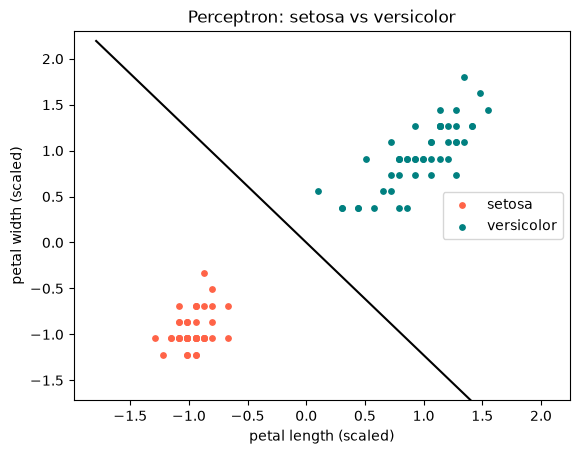

In [20]:
def plot_line(X, y, w, b, title, labels=("class 0", "class 1")):
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tomato", s=15, label=labels[0])
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c="teal", s=15, label=labels[1])
    xs = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 10)
    plt.plot(xs, -(w[0] * xs + b) / w[1], c="black")       # the line where z = 0
    plt.ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    plt.xlabel("petal length (scaled)")
    plt.ylabel("petal width (scaled)")
    plt.title(title)
    plt.legend()
    plt.show()

plot_line(X, y, w, b, "Perceptron: setosa vs versicolor", ("setosa", "versicolor"))

We try: Train on the iris data above with `eta` = 0.01, 0.1 and 1:
(a) starting from zero (the default), and (b) starting from `w0=[1.0, -1.0], b0=0.5`.
Print the mistakes per epoch. When does η matter, and why?

In [21]:
for eta in [0.01, 0.1, 1]:
    _, _, h_zero = train_perceptron(X, y, eta=eta)
    _, _, h_rand = train_perceptron(X, y, eta=eta, w0=[1.0, -1.0], b0=0.5)
    print(f"eta = {eta:<5} from zero: {h_zero}   from w0 = [1, -1], b0 = 0.5: {h_rand}")

# What we see:
# - From zero, every eta gives exactly the same run: [2, 0]. Starting at zero, w and b are always
#   eta times what they would be with eta = 1. That scales z but never changes its sign,
#   so every prediction and every mistake is the same.
# - From the random start, eta matters: 0.01 needs 10 epochs (25 mistakes in the first one),
#   0.1 and 1 need only 2. Tiny steps take a long time to move away from a bad start.
# - Lesson: for the plain perceptron, eta only matters when the weights don't start at zero.

eta = 0.01  from zero: [2, 0]   from w0 = [1, -1], b0 = 0.5: [25, 3, 3, 2, 2, 2, 1, 1, 1, 0]
eta = 0.1   from zero: [2, 0]   from w0 = [1, -1], b0 = 0.5: [5, 0]
eta = 1     from zero: [2, 0]   from w0 = [1, -1], b0 = 0.5: [2, 0]


## 4. More features: w₁, w₂, w₃, w₄
Our function works with any number of features, with no changes: `x` is just a longer list of numbers, and we get one weight per feature.
Here we use all **four** iris measurements.

In [23]:
X4f = StandardScaler().fit_transform(iris.data[mask])     # all 4 features, setosa vs versicolor
w4, b4, history4 = train_perceptron(X4f, y)

print("mistakes per epoch:", history4)
for name, weight in zip(iris.feature_names, w4):
    print(f"  {name:20s} w = {weight:5.2f}")
print("b =", b4)
print("training accuracy:", (predict(X4f, w4, b4) == y).mean())

mistakes per epoch: [2, 1, 0]
  sepal length (cm)    w =  1.46
  sepal width (cm)     w = -0.42
  petal length (cm)    w =  1.90
  petal width (cm)     w =  2.16
b = 1.0
training accuracy: 1.0


Four weights, one per feature. With 4 features the boundary is a flat "plane" in 4 dimensions: we can't draw it, but the perceptron doesn't care.
Because the features are scaled, the size of a weight shows how much the perceptron relies on that feature, and the sign shows which species it pushes towards
(positive → versicolor, negative → setosa).

## 5. When the classes overlap
Versicolor vs virginica overlap a little. Watch the mistakes per epoch.

epochs run: 40
training errors with the final weights: 6


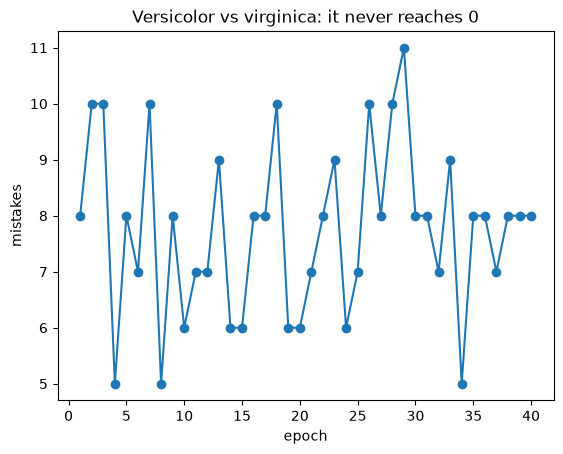

In [35]:
mask2 = species > 0                            # versicolor (1) and virginica (2)
X2 = StandardScaler().fit_transform(X_all[mask2])
y2 = (species[mask2] == 2).astype(int)         # virginica = 1, versicolor = 0

w2, b2, history2 = train_perceptron(X2, y2, epochs=40)
print("epochs run:", len(history2))
print("training errors with the final weights:", (predict(X2, w2, b2) != y2).sum())

plt.plot(range(1, len(history2) + 1), history2, marker="o")
plt.xlabel("epoch")
plt.ylabel("mistakes")
plt.title("Versicolor vs virginica: it never reaches 0")
plt.show()

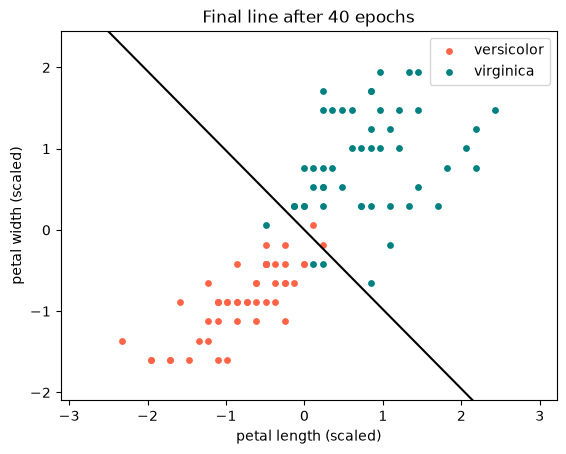

In [36]:
plot_line(X2, y2, w2, b2, "Final line after 40 epochs", ("versicolor", "virginica"))

**The pocket algorithm.** Change `train_perceptron` into `train_pocket` that, after every epoch,
counts the training errors of the current weights and keeps a copy of the **best** weights seen so far.
Return the best weights. How many errors do the best weights make on versicolor vs virginica, compared with the final weights?

final weights:   6 errors
pocket weights:  5 errors


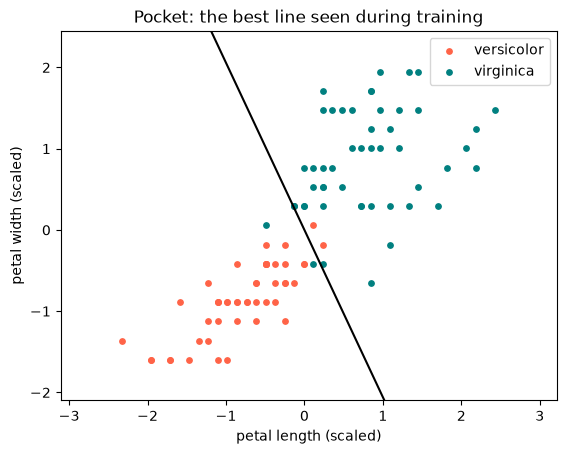

In [37]:
def train_pocket(X, y, eta=1.0, epochs=50, seed=0):
    rng = np.random.default_rng(seed)
    w, b = np.zeros(X.shape[1]), 0.0
    best_w, best_b, best_errors = w.copy(), b, len(X) + 1
    for epoch in range(epochs):
        mistakes = 0
        for i in rng.permutation(len(X)):
            y_hat = 1 if X[i] @ w + b > 0 else 0
            if y_hat != y[i]:
                w = w + eta * (y[i] - y_hat) * X[i]
                b = b + eta * (y[i] - y_hat)
                mistakes += 1
        errors = (predict(X, w, b) != y).sum()     # errors of the current weights
        if errors < best_errors:                   # better than anything so far: put it in the pocket
            best_w, best_b, best_errors = w.copy(), b, errors
        if mistakes == 0:
            break
    return best_w, best_b, best_errors

pw, pb, perr = train_pocket(X2, y2, epochs=40)
print("final weights:  ", (predict(X2, w2, b2) != y2).sum(), "errors")
print("pocket weights: ", perr, "errors")
plot_line(X2, y2, pw, pb, "Pocket: the best line seen during training", ("versicolor", "virginica"))

# What we see:
# - The final weights make 6 errors, the pocket weights 5.
# - On overlapping data the final weights are just wherever training happened to stop.
#   The pocket keeps the best weights seen, so we never end up worse than the best we found.
# - The difference is small here, but it can be much larger on other data or with other seeds.
# - Note: these are errors on the TRAINING data. To judge the model, check it on test data too.

## 6. Compare with scikit-learn, and more than two classes
scikit-learn's `Perceptron` uses the same rule. With all three species, it trains one perceptron per species (one-vs-rest)
and picks the class with the largest z.

In [39]:
X3 = StandardScaler().fit_transform(X_all)
sk = Perceptron(random_state=0).fit(X3, species)

print("one row of weights per species:\n", sk.coef_.round(2))
print("training accuracy:", round(sk.score(X3, species), 3))

flower = X3[:1]                                    # the first flower (a setosa)
print("z for each species:", sk.decision_function(flower).round(1))
print("prediction:", iris.target_names[sk.predict(flower)[0]])

one row of weights per species:
 [[-1.5  -1.19]
 [ 2.98 -0.66]
 [ 3.77  3.68]]
training accuracy: 0.867
z for each species: [[  2.6  -2.1 -13.9]]
prediction: setosa


The accuracy on all three species is lower: versicolor and virginica overlap, so the "versicolor or not?" perceptron can't find a good line.
This is exactly the limit from the lecture, and one reason we move on to logistic regression and neural networks.

## 7. Apples, oranges and pears: one score per class
Simulated fruit where pears lie **between** apples and oranges. Two ways to handle three classes:
- **One-vs-rest** (scikit-learn): three separate yes/no perceptrons
- **One weight vector per class, trained together**: when it guesses wrong, add to the right class and subtract from the guessed class

In [40]:
r = np.random.default_rng(5)
apples  = np.column_stack([r.normal(155, 12, 40), r.normal(11.0, 0.8, 40)])   # light, sweet
oranges = np.column_stack([r.normal(210, 14, 40), r.normal(8.0, 0.8, 40)])    # heavy, less sweet
pears   = np.column_stack([r.normal(182, 10, 40), r.normal(9.5, 0.6, 40)])    # in between
fruit_names = ["apple", "orange", "pear"]
Xf = StandardScaler().fit_transform(np.vstack([apples, oranges, pears]))
yf = np.array([0] * 40 + [1] * 40 + [2] * 40)

# one-vs-rest: also check each yes/no question on its own
ovr = Perceptron(random_state=0, max_iter=1000).fit(Xf, yf)
print(f"one-vs-rest, all three classes: {ovr.score(Xf, yf):.0%} correct")
for k, name in enumerate(fruit_names):
    single = Perceptron(random_state=0, max_iter=1000).fit(Xf, (yf == k).astype(int))
    print(f"   '{name} or not?' on its own: {single.score(Xf, (yf == k).astype(int)):.0%}")

one-vs-rest, all three classes: 82% correct
   'apple or not?' on its own: 97%
   'orange or not?' on its own: 94%
   'pear or not?' on its own: 49%


In [42]:
def train_multiclass(X, y, n_classes, epochs=200, seed=0):
    rng = np.random.default_rng(seed)
    W = np.zeros((n_classes, X.shape[1]))         # one weight vector per class
    B = np.zeros(n_classes)                       # one bias per class
    for epoch in range(epochs):
        mistakes = 0
        for i in rng.permutation(len(X)):
            guess = np.argmax(W @ X[i] + B)       # the class with the highest score
            if guess != y[i]:
                W[y[i]] += X[i];  B[y[i]] += 1    # push the right class up
                W[guess] -= X[i]; B[guess] -= 1   # push the wrong guess down
                mistakes += 1
        if mistakes == 0:
            break
    return W, B

W, B = train_multiclass(Xf, yf, n_classes=3)
pred = np.argmax(Xf @ W.T + B, axis=1)
print(f"one weight vector per class: {(pred == yf).mean():.0%} correct")

one weight vector per class: 87% correct


"Pear or not?" fails on its own: no single straight line puts the pears on one side and both apples **and** oranges on the other.
Training the three weight vectors together works better, because pears only need to score **highest** in their own area.
Some fruits overlap, so it never reaches 100 % (and never stops by itself: hence `epochs=200`).

## Summary
- The perceptron is a few lines of NumPy: predict, update only when wrong, stop after an epoch with no mistakes.
- On separable data it stops. On overlapping data it never does, so set a maximum and keep the best weights.
- The learning rate only matters when the weights don't start at zero.
- More classes: one score per class, and the highest score wins.